<div class="cover">

# Lab 2 — Text Preprocessing and Regular Expressions

**Name:** Omar Hejazi<br>
**Student ID:** 2230009001<br>
**Dataset:** Apple Twitter Sentiment Texts

</div>


**Task.** Using the Apple Twitter sentiment dataset, find how many hashtags there are and the top 10
hashtags used in the dataset.

Dataset: `seriousran/appletwittersentimenttexts` on Kaggle.

After the hashtag task I apply the full preprocessing pipeline from the lab (tokenisation,
lowercasing, stopword removal, stemming, lemmatisation) to the same tweets and measure what each
step actually does to the vocabulary.

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import pandas as pd

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

DATA_DIR = Path("data")
pd.set_option("display.max_colwidth", 140)

In [2]:
csv_path = DATA_DIR / "apple-twitter-sentiment-texts.csv"

if not csv_path.exists():
    import kagglehub

    cache = kagglehub.dataset_download("seriousran/appletwittersentimenttexts")
    csv_path = next(Path(cache).glob("*.csv"))

tweets = pd.read_csv(csv_path, encoding="utf-8-sig")
print(tweets.shape)
tweets.head()

(1630, 2)


,text,sentiment
0,Wow. Yall needa step it up @Apple RT @heynyla: Music and snapchat at the same damn time. Thank you #Note4,-1
1,What Happened To Apple Inc? http://t.co/FJEXI3oP0U #aapl #apple @MoneyPress http://t.co/wXKmmTMArW,0
2,Thank u @apple I can now compile all of the pics that i communicate with in one place http://t.co/tq1lo09oyA,1
3,The oddly uplifting story of the Apple co-founder who sold his stake for $800 \r\n$AAPL #aapl\r\nhttp://t.co/CiZbVR05PJ,0
4,@apple can i exchange my iphone for a different color lmao i changed my mind,0


The file is saved with a UTF-8 byte-order mark, so reading it with plain `utf-8` names the first
column `'﻿text'` instead of `'text'`. Passing `encoding="utf-8-sig"` strips the mark. This is a
small thing, but it is the kind of detail that silently breaks a `df["text"]` lookup later.

In [3]:
print("Columns:", tweets.columns.tolist())
print("\nSentiment labels (-1 negative, 0 neutral, 1 positive):")
print(tweets["sentiment"].value_counts().sort_index())

Columns: ['text', 'sentiment']

Sentiment labels (-1 negative, 0 neutral, 1 positive):
sentiment
-1    686
 0    801
 1    143
Name: count, dtype: int64


## Extracting the hashtags

A hashtag is a `#` followed by word characters. `\w` covers `[A-Za-z0-9_]`, which is exactly what
Twitter allows in a tag, so `#\w+` is the whole pattern — with one caveat: `\w+` is greedy and will
happily match a tag that is only digits (`#4`), which Twitter does not actually treat as a hashtag.
Requiring at least one letter is a more faithful rule.

In [4]:
HASHTAG = re.compile(r"#\w*[A-Za-z]\w*")

tweets["hashtags"] = tweets["text"].apply(HASHTAG.findall)
tweets.loc[tweets["hashtags"].str.len() > 0, ["text", "hashtags"]].head()

,text,hashtags
0,Wow. Yall needa step it up @Apple RT @heynyla: Music and snapchat at the same damn time. Thank you #Note4,[#Note4]
1,What Happened To Apple Inc? http://t.co/FJEXI3oP0U #aapl #apple @MoneyPress http://t.co/wXKmmTMArW,"[#aapl, #apple]"
3,The oddly uplifting story of the Apple co-founder who sold his stake for $800 \r\n$AAPL #aapl\r\nhttp://t.co/CiZbVR05PJ,[#aapl]
5,RT @JPDesloges: Apple Acted Unfairly In Suppressing Digital Music Competition: Paul Kedrosky $AAPL #aapl\r\nhttp://t.co/XTbFhpbYf7,[#aapl]
7,Apple Inc. Deleted Songs From Rival Services From iPods http://t.co/dQwDFpcc4x #AAPL,[#AAPL]


In [5]:
all_hashtags = [tag for row in tweets["hashtags"] for tag in row]
tagged_tweets = (tweets["hashtags"].str.len() > 0).sum()

print(f"Tweets in the dataset:        {len(tweets):,}")
print(f"Tweets containing a hashtag:  {tagged_tweets:,} ({tagged_tweets / len(tweets):.1%})")
print(f"Total hashtag occurrences:    {len(all_hashtags):,}")
print(f"Distinct hashtags (as typed): {len(set(all_hashtags)):,}")

Tweets in the dataset:        1,630
Tweets containing a hashtag:  783 (48.0%)
Total hashtag occurrences:    1,605
Distinct hashtags (as typed): 602


### Why the count "as typed" is the wrong answer

`#AAPL` and `#aapl` are the same hashtag — Twitter treats tags case-insensitively. Counting the raw
strings therefore splits every popular tag across several spellings:

In [6]:
raw_counts = Counter(all_hashtags)
pd.DataFrame(raw_counts.most_common(8), columns=["hashtag (as typed)", "count"])

,hashtag (as typed),count
0,#AAPL,203
1,#aapl,197
2,#Apple,134
3,#December,37
4,#iPhone,33
5,#apple,27
6,#iPhone6,24
7,#Monday,9


`#AAPL` (203) and `#aapl` (197) are two rows in that table and would rank 1st and 2nd as if they were
different topics. Lowercasing merges them into a single tag with 400 occurrences — a genuinely
different picture of what the dataset is about.

This is the clearest possible argument for the *lower casing* step in the preprocessing pipeline: it
is not cosmetic, it changes the answer.

In [7]:
counts = Counter(tag.lower() for tag in all_hashtags)

print(f"Distinct hashtags, as typed:      {len(raw_counts):,}")
print(f"Distinct hashtags, lowercased:    {len(counts):,}")
print(f"Collapsed by case normalisation:  {len(raw_counts) - len(counts):,}")

Distinct hashtags, as typed:      602
Distinct hashtags, lowercased:    550
Collapsed by case normalisation:  52


## Answer: the top 10 hashtags

In [8]:
top10 = pd.DataFrame(counts.most_common(10), columns=["hashtag", "count"])
top10["share of all hashtags"] = (top10["count"] / len(all_hashtags)).map("{:.1%}".format)
top10

,hashtag,count,share of all hashtags
0,#aapl,400,24.9%
1,#apple,162,10.1%
2,#iphone,38,2.4%
3,#december,37,2.3%
4,#iphone6,29,1.8%
5,#stocks,15,0.9%
6,#ipad,14,0.9%
7,#iphone6plus,13,0.8%
8,#iphone6s,13,0.8%
9,#tech,12,0.7%


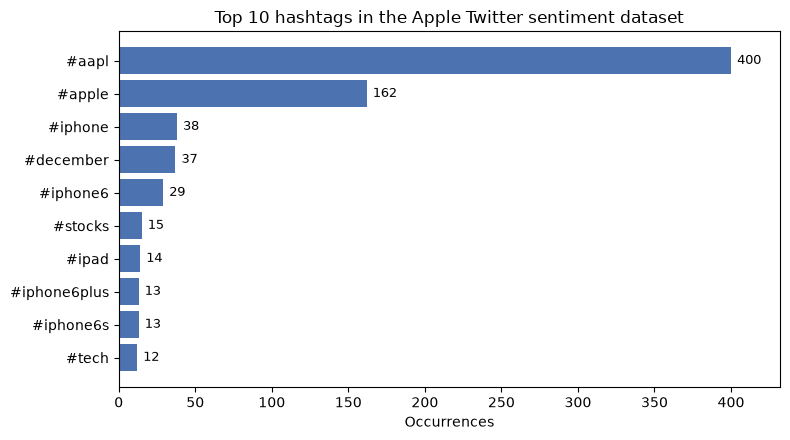

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top10["hashtag"][::-1], top10["count"][::-1], color="#4c72b0")
ax.set_xlabel("Occurrences")
ax.set_title("Top 10 hashtags in the Apple Twitter sentiment dataset")
for y, v in enumerate(top10["count"][::-1]):
    ax.text(v + 4, y, str(v), va="center", fontsize=9)
ax.margins(x=0.08)
plt.tight_layout()
plt.show()

`#aapl` alone accounts for a quarter of every hashtag in the corpus, and together with `#apple` the
top two cover 35%. `#aapl` is Apple's stock ticker, and the rest of the head — `#stocks`,
`#trading` — points the same way: a large share of these tweets are financial commentary rather than
consumer opinion about products.

The tail behaves the way word frequencies usually do:

In [10]:
occurrences = pd.Series(list(counts.values()))
print(f"Hashtags used exactly once: {(occurrences == 1).sum():,} of {len(counts):,} "
      f"({(occurrences == 1).mean():.0%})")
print(f"Top 10 hashtags account for {top10['count'].sum() / len(all_hashtags):.0%} of all occurrences")

Hashtags used exactly once: 402 of 550 (73%)
Top 10 hashtags account for 46% of all occurrences


Roughly three quarters of distinct hashtags appear only once while ten tags cover just under half
the volume — a Zipf-like distribution. For feature extraction this matters: the single-occurrence tags carry
almost no signal a model could generalise from, and they are what `min_df` in a vectoriser is there
to drop.

---

## Applying the preprocessing pipeline

The hashtag task only needed a regular expression. The rest of the lab is the standard pipeline, so
below I apply each step to the tweet text and measure its effect on the vocabulary instead of just
demonstrating it on one sentence.

In [11]:
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

STOPWORDS = set(stopwords.words("english"))
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

URL = re.compile(r"https?://\S+|www\.\S+")
MENTION = re.compile(r"@\w+")
RT = re.compile(r"\bRT\b:?")
NON_LETTER = re.compile(r"[^a-z\s]")


def clean(text):
    # Strip the Twitter-specific noise that would otherwise become vocabulary.
    text = URL.sub(" ", text)
    text = MENTION.sub(" ", text)
    text = RT.sub(" ", text)
    text = HASHTAG.sub(lambda m: m.group()[1:], text)  # keep the word, drop the '#'
    return re.sub(r"\s+", " ", text).strip()

Two decisions in `clean` are worth stating explicitly:

- **Mentions are removed, hashtags are not.** `@MoneyPress` is a routing artefact and means nothing
  outside the thread it was posted in. `#iphone6` is a topic word, so I keep the word and drop only
  the `#`.
- **URLs go entirely.** A shortened `t.co` link carries no lexical information at all.

In [12]:
example = tweets.loc[1, "text"]
print("raw:    ", example)
print("cleaned:", clean(example))

raw:     What Happened To Apple Inc?   http://t.co/FJEXI3oP0U  #aapl #apple @MoneyPress http://t.co/wXKmmTMArW
cleaned: What Happened To Apple Inc? aapl apple


In [13]:
def pipeline(text, remove_stopwords=True, mode="lemma"):
    tokens = word_tokenize(NON_LETTER.sub(" ", clean(text).lower()))
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS]
    tokens = [t for t in tokens if len(t) > 1]
    if mode == "stem":
        tokens = [stemmer.stem(t) for t in tokens]
    elif mode == "lemma":
        tokens = [lemmatizer.lemmatize(t, pos="v") for t in tokens]
    return tokens


print(pipeline("RT @heynyla: Apple's new iPhones are running BETTER than I expected!! #iPhone6 http://t.co/abc"))

['apple', 'new', 'iphones', 'run', 'better', 'expect', 'iphone']


### Measuring each step

Each stage of the pipeline is supposed to shrink the vocabulary without destroying meaning. The
table below makes that trade-off visible.

In [14]:
def vocab_size(tokeniser):
    vocab = set()
    for text in tweets["text"]:
        vocab.update(tokeniser(text))
    return len(vocab)


stages = {
    "raw split on whitespace": lambda t: t.split(),
    "+ cleaning (urls, mentions)": lambda t: clean(t).split(),
    "+ lowercase, letters only": lambda t: pipeline(t, remove_stopwords=False, mode=None),
    "+ stopword removal": lambda t: pipeline(t, remove_stopwords=True, mode=None),
    "+ lemmatisation": lambda t: pipeline(t, remove_stopwords=True, mode="lemma"),
    "+ stemming (instead)": lambda t: pipeline(t, remove_stopwords=True, mode="stem"),
}

report = pd.DataFrame(
    [(name, vocab_size(fn)) for name, fn in stages.items()],
    columns=["stage", "vocabulary size"],
)
report["reduction vs raw"] = (1 - report["vocabulary size"] / report["vocabulary size"].iloc[0]).map("{:.0%}".format)
report

,stage,vocabulary size,reduction vs raw
0,raw split on whitespace,7660,0%
1,"+ cleaning (urls, mentions)",6123,20%
2,"+ lowercase, letters only",3715,52%
3,+ stopword removal,3587,53%
4,+ lemmatisation,3073,60%
5,+ stemming (instead),2899,62%


The pipeline cuts the vocabulary by about 60%. Almost all of that comes from the first two steps —
removing URLs and mentions (20%), then lowercasing and dropping non-letters (a further 32 points).
Stopword removal contributes barely one point, because there are only ~180 stopwords to begin with
and they are high-*frequency*, not high-*variety*: they cost a lot of tokens but almost no
vocabulary.

That ordering is worth noting, because stemming is the step that costs the most readability and
contributes among the least reduction.

In [15]:
comparison = pd.DataFrame({"word": ["running", "runner", "easily", "studies", "generously", "was"]})
comparison["stem"] = comparison["word"].map(stemmer.stem)
comparison["lemma (verb)"] = comparison["word"].map(lambda w: lemmatizer.lemmatize(w, pos="v"))
comparison

,word,stem,lemma (verb)
0,running,run,run
1,runner,runner,runner
2,easily,easili,easily
3,studies,studi,study
4,generously,gener,generously
5,was,wa,be


Stemming is a string operation and produces non-words (`easili`, `generous` → `gener`);
lemmatisation consults WordNet and returns real dictionary forms. For this dataset, where I later
want to *read* the frequent terms, lemmatisation is the better choice — the output stays
interpretable.

### A caution about stopword removal

The lab notes that stopword removal is not always appropriate. This dataset is labelled for
sentiment, which is precisely the case where it does damage, because NLTK's English stopword list
contains most of the negations:

In [16]:
negations = ["not", "no", "nor", "don't", "doesn't", "isn't", "wasn't", "never"]
pd.DataFrame({
    "word": negations,
    "in NLTK stopword list": [w in STOPWORDS for w in negations],
})

,word,in NLTK stopword list
0,not,True
1,no,True
2,nor,True
3,don't,True
4,doesn't,True
5,isn't,True
6,wasn't,True
7,never,False


In [17]:
review = "the new iPhone is not good at all"
print("kept:   ", pipeline(review, remove_stopwords=False, mode=None))
print("removed:", pipeline(review, remove_stopwords=True, mode=None))

kept:    ['the', 'new', 'iphone', 'is', 'not', 'good', 'at', 'all']
removed: ['new', 'iphone', 'good']


Note that the list is not even consistent — `not`, `no` and `nor` are stopwords but `never` is not,
so the default recipe strips some negations and keeps others.

The effect on a sentiment example is direct: `"not good"` becomes `"good"`. A classifier trained on
the second version has been handed the exact opposite of the truth. If I were building a sentiment
model on these tweets I would either
keep stopwords entirely or subtract the negations from the list first:

```python
KEEP = {"not", "no", "nor", "never", "n't"}
STOPWORDS_FOR_SENTIMENT = STOPWORDS - KEEP
```

I use exactly that adjustment in Lab 4.

### Most frequent terms after preprocessing

In [18]:
token_counts = Counter()
for text in tweets["text"]:
    token_counts.update(pipeline(text))

pd.DataFrame(token_counts.most_common(15), columns=["token", "count"])

,token,count
0,aapl,528
1,apple,491
2,iphone,263
3,fuck,136
4,phone,123
5,get,116
6,new,86
7,make,80
8,thank,67
9,store,67


The head of this list is the same story the hashtags told: `aapl`, `apple` and `iphone` dominate, and
the ticker outranks the company name.

Two things in the list are worth flagging as preprocessing bugs rather than findings. `amp` is the
remains of the HTML entity `&amp;` — the `&` and `;` were stripped by the letters-only step, leaving
a fake word behind. `inc` comes from "Apple Inc". Catching the first would need an entity-unescaping
step *before* punctuation removal:

```python
import html
text = html.unescape(text)   # "&amp;" -> "&", which then gets stripped as punctuation
```

This is a good illustration of why step order matters in a pipeline: removing punctuation first
turned a recoverable entity into a permanent piece of noise.

## Summary

- **1,605 hashtag occurrences** across 1,630 tweets, appearing in **783 tweets (48%)**.
- **602 distinct hashtags as typed, 550 after lowercasing** — case normalisation alone merges 52 of
  them, including the `#AAPL`/`#aapl` pair that would otherwise have taken both top spots.
- **Top 10:** `#aapl`, `#apple`, `#iphone`, `#december`, `#iphone6`, `#stocks`, `#ipad`,
  `#iphone6plus`, `#iphone6s`, `#tech` — 46% of the hashtag volume, and clearly skewed toward
  stock-market rather than product discussion.
- The full pipeline reduces the vocabulary by about 60%, but most of the reduction comes from
  cleaning and lowercasing rather than from stemming, and stopword removal would actively harm the
  sentiment labels this dataset ships with.